# Installation


**Conda Environment**
- conda create -n gemini_env
- conda activate gemini_env
- conda install -c conda-forge google-generativeai pillow ipykernel jupyterlab notebook python=3.11

**Install Pytorch:**
python -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

**Verify:**
python -c "import torch; print(torch.cuda.is_available()); print(torch.cuda.get_device_name(0))"

**Registers your environment as a Jupyter kernel:**
python -m ipykernel install --user --name=gemini_env


In [3]:
#!pip install -U google-generativeai pillow numpy opencv-python jiwer

In [4]:
#!pip install torch torchvision torchaudio matplotlib pandas pillow requests

### Setting Up API Key and Launching JupyterLab

Open the terminal and run the following commands:

- cd Gemini 
  Replace "Gemini" with the name of your project folder if it is different.

- conda activate gemini_env  
  Activate the Conda environment we created earlier.

- $env:GEMINI_API_KEY="YourSecretAPIkey"  
  Replace "YourSecretAPIkey" with your actual gemini API key.

- jupyter lab  
  Next step, Write jupyter lab in the terminal to Launch JupyterLab in the browser.

In [2]:
from google import genai
import os

client = genai.Client(api_key=os.environ.get("GEMINI_API_KEY"))

response = client.models.generate_content(
    model="gemini-3.1-pro-preview", 
    contents="Hello from my Jupyter notebook!"
)

print(response.text)

Hello right back! 👋 

```python
print("How can I help you today?")
```

Are you working on some data analysis, machine learning, debugging some Python code, or something else entirely? Let me know what you're building!


In [9]:
# verify key
#import os
#print(os.getenv("GEMINI_API_KEY"))

In [4]:
import sys
import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Torch CUDA:", torch.version.cuda)


Torch version: 2.2.0+cu118
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Torch CUDA: 11.8


In [5]:
import torch
from PIL import Image
import matplotlib.pyplot as plt
import requests
import pandas as pd
import re
from jiwer import wer, cer

# Image Download

In [6]:
import os
import platform

pages = [8, 9, 12, 38, 53, 78, 94, 105, 114, 115,
         210, 314, 316, 384, 457, 468, 490, 619, 615, 753]

base = "https://nlp.fi.muni.cz/projekty/ahisto/book_by_id/494/"

os.makedirs("images", exist_ok=True)
os_type = platform.system()
print("OS: ", os_type)

for p in pages:
    path = f"images/{p}.jpg"
    
    if not os.path.exists(path):
        if os_type == "Windows":
            # !curl -o {path} {base}{p}.jpg
            !curl -k -L -o {path} {base}{p}.jpg # ignore certificate verification, follow redirects
        else:
            !wget -O {path} {base}{p}.jpg
    else:
        print(f"Already exists: {path}")

OS:  Windows
Already exists: images/8.jpg
Already exists: images/9.jpg
Already exists: images/12.jpg
Already exists: images/38.jpg
Already exists: images/53.jpg
Already exists: images/78.jpg
Already exists: images/94.jpg
Already exists: images/105.jpg
Already exists: images/114.jpg
Already exists: images/115.jpg
Already exists: images/210.jpg
Already exists: images/314.jpg
Already exists: images/316.jpg
Already exists: images/384.jpg
Already exists: images/457.jpg
Already exists: images/468.jpg
Already exists: images/490.jpg
Already exists: images/619.jpg
Already exists: images/615.jpg
Already exists: images/753.jpg


# Gemini-3.1-Pro OCR - Prompt and Function

In [8]:
prompt_text_0 = "Extract all text from this image exactly as written. Preserve line breaks."

In [7]:
prompt_text_2 = """
You are an OCR specialist.

Extract every visible character from this image exactly as it appears.

Return plain text only. Preserve the original reading order, line breaks, paragraph breaks, headings, punctuation, capitalization, spelling, abbreviations, umlauts, ß, Roman numerals, page numbers, and hyphenation exactly as printed.

Do not correct spelling or grammar. Do not modernize, normalize, translate, summarize, explain, or infer missing text. Do not merge words that are split by line-ending hyphens.

If any character or word cannot be read with confidence, write [illegible] exactly at that position instead of guessing.

Do not include any #, comments, Markdown, labels, or additional text. Return only the transcription.
"""

In [9]:
import os
from google import genai
from google.genai import types


def run_ocr_one_image(image_path, prompt_text):
    with open(image_path, "rb") as f:
        image_bytes = f.read()

    response = client.models.generate_content(
        model="gemini-3.1-pro-preview",
        contents=[
            prompt_text,
            types.Part.from_bytes(
                data=image_bytes,
                mime_type="image/jpeg"
            )
        ]
    )

    return response.text

# Experiment 1 - Clean Baseline
Original image to OCR, Without preprocessing

In [12]:
import os

output_dir = "outputs/Experiment_1"
os.makedirs(output_dir, exist_ok=True)

In [19]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"images/{p}.jpg"
    output_path = os.path.join(output_dir, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_2)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprecht's ist. Hiemit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nennen 

### Evaluation Experiment 1

In [64]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [65]:
results_exp1 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    #compute metrics
    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp1.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating page 8...
Evaluating page 9...
Evaluating page 12...
Evaluating page 38...
Evaluating page 53...
Evaluating page 78...
Evaluating page 94...
Evaluating page 105...
Evaluating page 114...
Evaluating page 115...
Evaluating page 210...
Evaluating page 314...
Evaluating page 316...
Evaluating page 384...
Evaluating page 457...
Evaluating page 468...
Evaluating page 490...
Evaluating page 619...
Evaluating page 615...
Evaluating page 753...


In [66]:
print("=== Experiment 1 Results: Gemini-3.1-Pro ===")
df_exp1 = pd.DataFrame(results_exp1)
df_exp1

=== Experiment 1 Results: Gemini-3.1-Pro ===


,page,WER,CER
0,8,0.014888,0.002232
1,9,0.007117,0.001622
2,12,0.028169,0.010973
3,38,0.103858,0.030562
4,53,0.036735,0.014746
5,78,0.517986,0.390326
6,94,0.217172,0.095676
7,105,0.280835,0.189748
8,114,0.129542,0.049446
9,115,0.045677,0.022444


In [67]:
mean_wer = df_exp1["WER"].mean()
mean_cer = df_exp1["CER"].mean()

print("=== Experiment 1 Results - Gemini-3.1-Pro ===")
print(f"Mean WER: {mean_wer:.4f}")
print(f"Mean CER: {mean_cer:.4f}")

=== Experiment 1 Results - Gemini-3.1-Pro ===
Mean WER: 0.0963
Mean CER: 0.0495


### Save result

In [68]:
import os

output_dir_result_1 = "outputs/Results"
os.makedirs(output_dir_result_1, exist_ok=True)

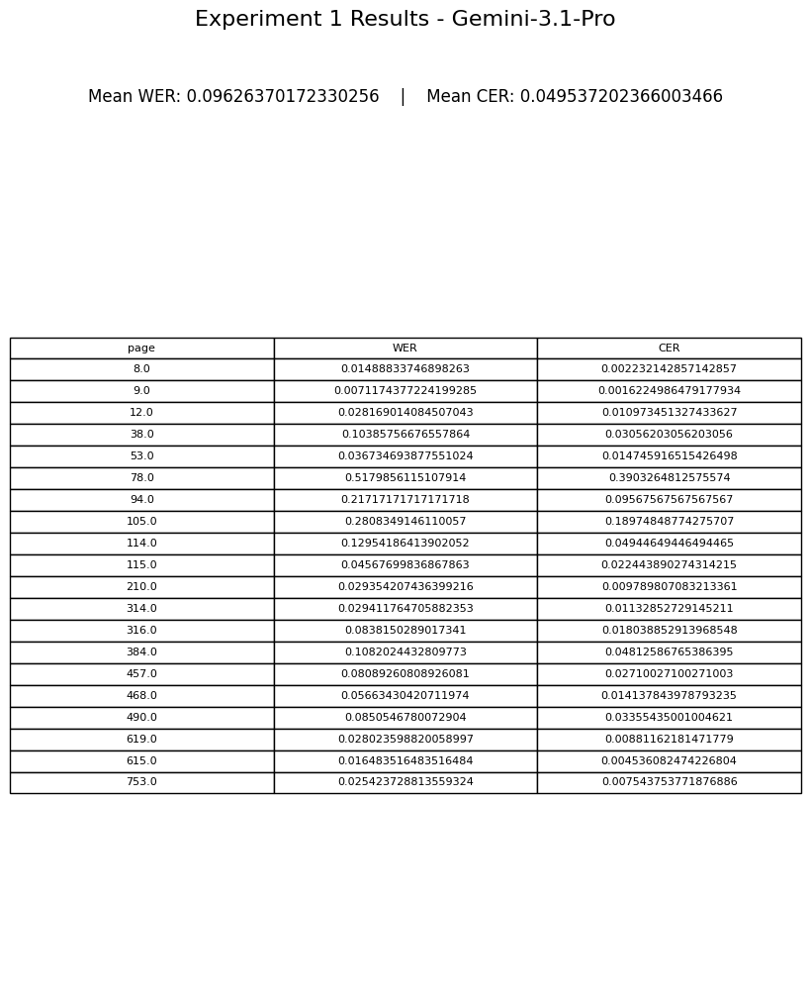

Saved: outputs/Results\experiment_1_results.png


In [69]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp1["WER"].mean()
mean_cer = df_exp1["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_1_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp1) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 1 Results - Gemini-3.1-Pro", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)

# Table
table = ax.table(
    cellText=df_exp1.values,
    colLabels=df_exp1.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

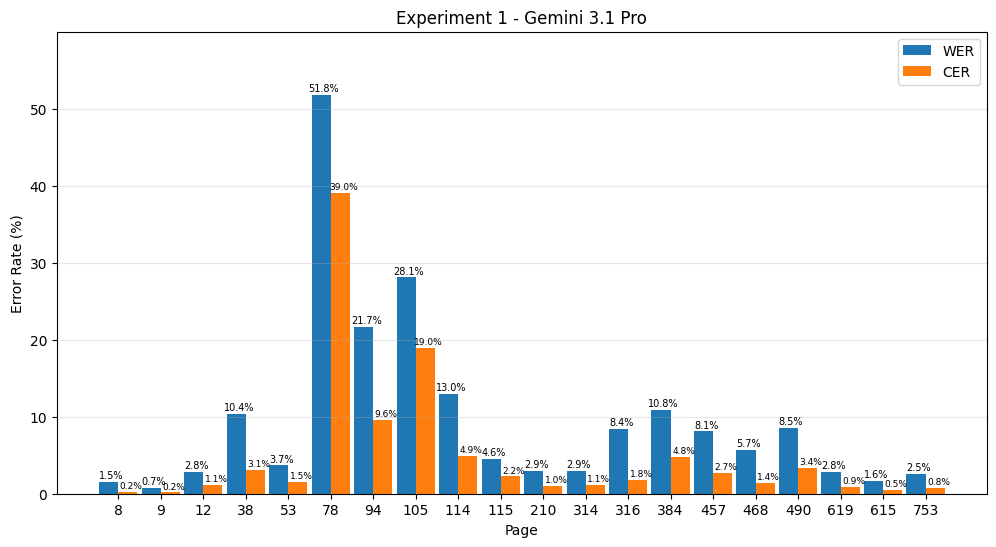

In [96]:
import numpy as np
x = np.arange(len(df_exp1))
width = 0.45

wer_pct = df_exp1["WER"] * 100
cer_pct = df_exp1["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp1["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 1 - Gemini 3.1 Pro")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 60)
plt.yticks(np.arange(0, 51, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_1_gemini_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 2 - Noise
Salt and Pepper, Nosify, Distortion - Without Preprocessing

In [19]:
import os

output_dir_2 = "outputs/Experiment_2"
os.makedirs(output_dir_2, exist_ok=True)

### Salt and Pepper Function

Salt-and-pepper noise was implemented based on standard image processing techniques as described in (https://www.geeksforgeeks.org/python/add-a-salt-and-pepper-noise-to-an-image-with-python/)

In [20]:
import numpy as np
from PIL import Image


# amount = how many pixels change
# amount = 0.2 -- 20% pixel changed, amount = 0.8 -- 80% pixel changed
# salt_vs_pepper = how many are white
# salt_vs_pepper = 0.2 -- 20% white, salt_vs_pepper = 0.8 -- 80% white


def add_salt_pepper(image, amount=0.005, salt_vs_pepper=0.5):

    img = np.array(image).copy()
    h, w = img.shape[:2]

    num_pixels = int(amount * h * w)
    num_salt = int(num_pixels * salt_vs_pepper)
    num_pepper = num_pixels - num_salt

    #salt -white
    ys = np.random.randint(0, h, num_salt)
    xs = np.random.randint(0, w, num_salt)
    img[ys, xs] = 255

    #pepper -black
    ys = np.random.randint(0, h, num_pepper)
    xs = np.random.randint(0, w, num_pepper)
    img[ys, xs] = 0

    return Image.fromarray(img)

### Image_Distortion
The image distortion functions are adapted from the Image_Distortion repository(https://github.com/namks/Image_Distortion/tree/main), specifically the zoom and resolution degradation methods.

In [21]:
from PIL import Image

def zoom_img(image, zoom_scale=1.15):
    w, h = image.size
    x = w / 2
    y = h / 2

    cropped = image.crop((
        x - w / (2 * zoom_scale),
        y - h / (2 * zoom_scale),
        x + w / (2 * zoom_scale),
        y + h / (2 * zoom_scale)
    ))

    return cropped.resize((w, h), Image.BICUBIC)

def lower_res_img(image, scale=0.7):
    w, h = image.size
    low_res = image.resize((int(w * scale), int(h * scale)), Image.BICUBIC)
    return low_res.resize((w, h), Image.BICUBIC)

def add_image_distortion(image, zoom_scale=1.15, resolution_scale=0.7):
    image = zoom_img(image, zoom_scale=zoom_scale)
    image = lower_res_img(image, scale=resolution_scale)
    return image

### Noisy
Additional blurring effects were applied to simulate realistic degradation, inspired by data augmentation techniques such as Noisify
(https://github.com/dstl/Noisify)

In [22]:
import cv2
import numpy as np
from PIL import Image

def add_blur(image, kernel_size=3):
    img = np.array(image)
    blurred = cv2.GaussianBlur(img, (kernel_size, kernel_size), 0)
    return Image.fromarray(blurred)

### Testing one image with Noise

#### Test Salt and Pepper

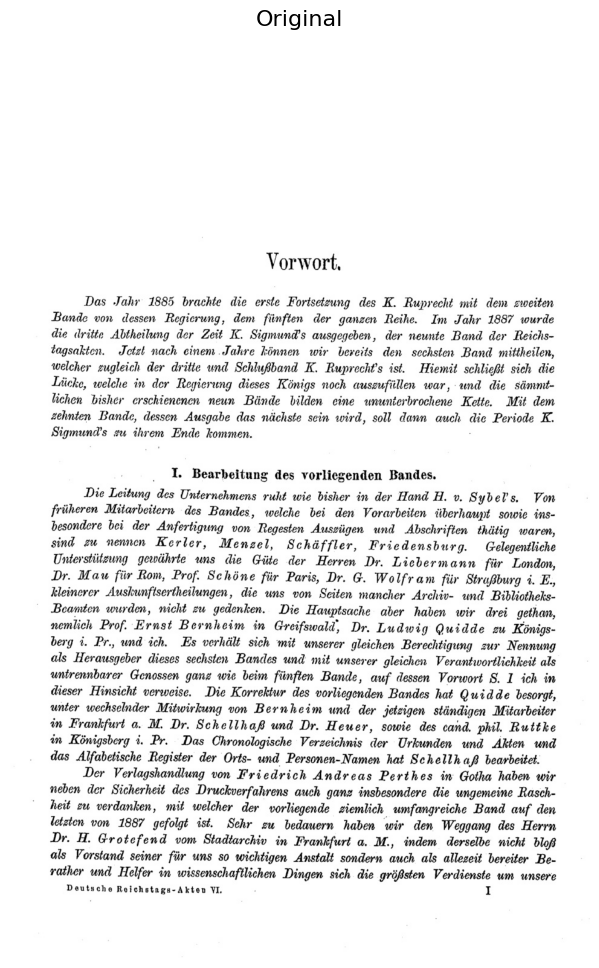

In [23]:
from PIL import Image
import matplotlib.pyplot as plt

noise_image_test = "images/8.jpg"

img = Image.open(noise_image_test).convert("RGB")

plt.figure(figsize=(10,12))
plt.imshow(img)
plt.title("Original", fontsize=16)
plt.axis("off")
plt.show()

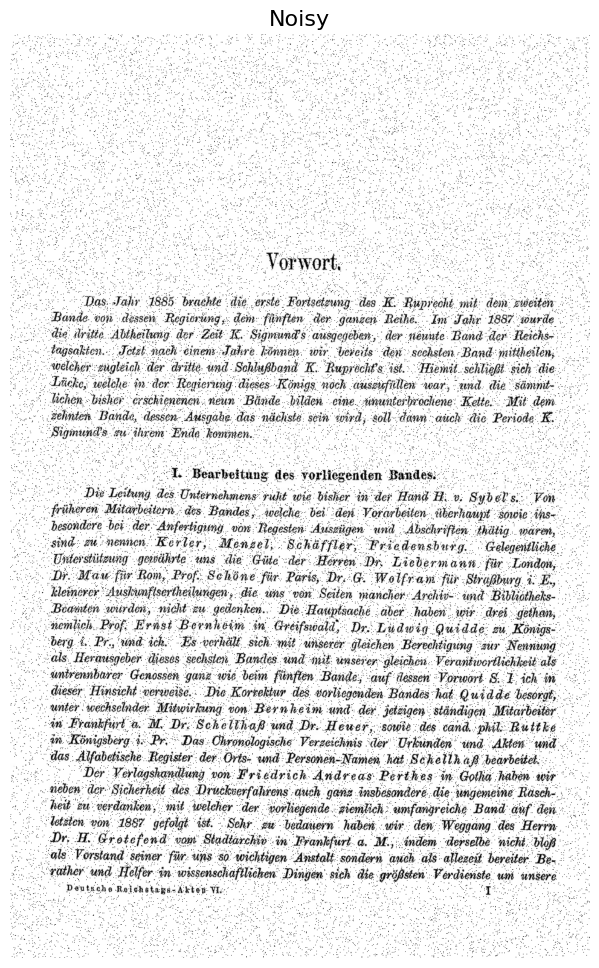

In [24]:
noisy_img = add_salt_pepper(img, amount=0.04,salt_vs_pepper=0.3)
plt.figure(figsize=(10,12))
plt.imshow(noisy_img)
plt.title("Noisy", fontsize=16)
plt.axis("off")
plt.show()

#### Test Image Distortion and BLurr

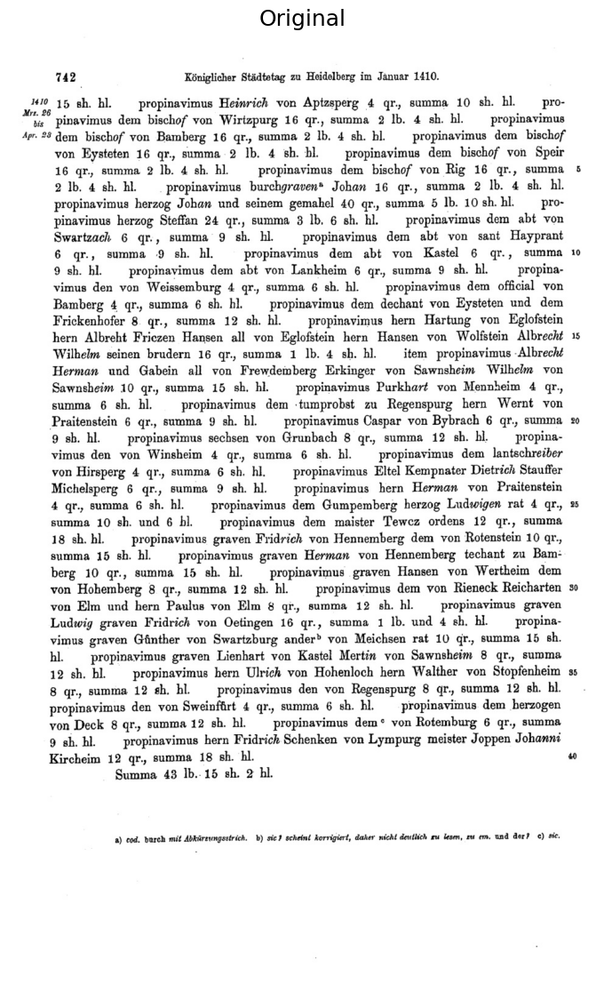

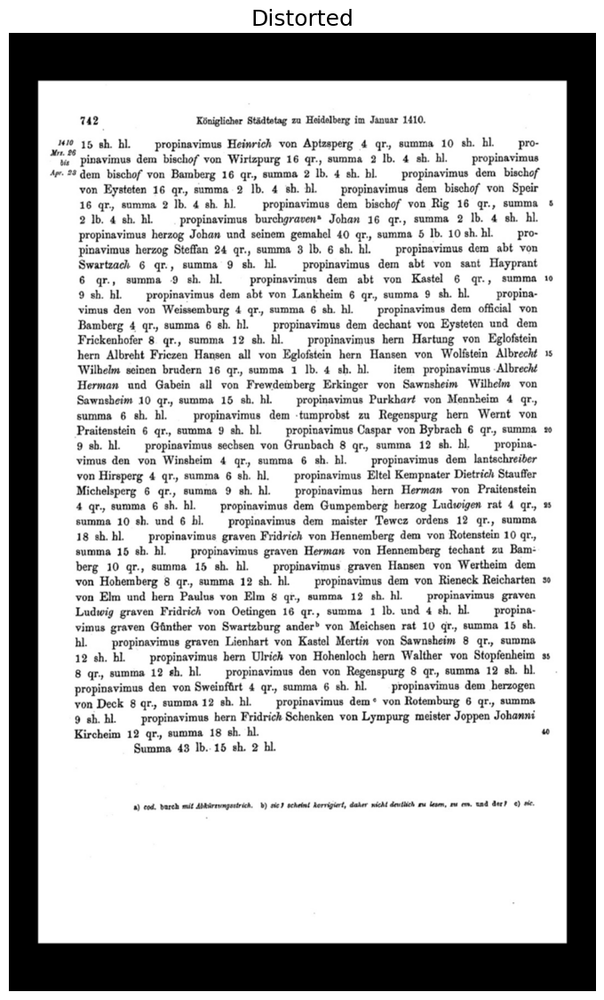

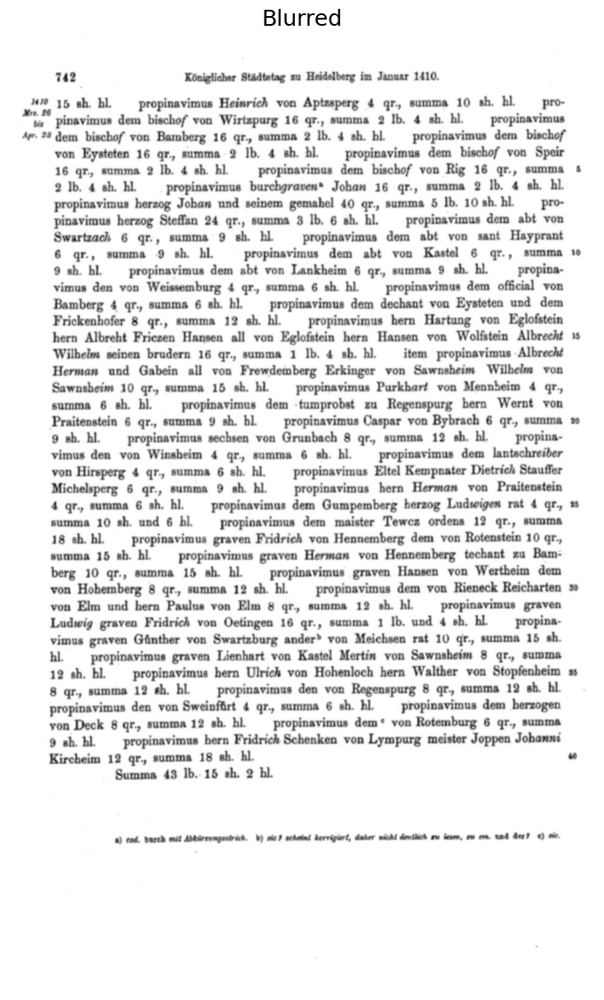

In [25]:
from PIL import Image
import matplotlib.pyplot as plt

noise_image_test2 = "images/753.jpg"
img1 = Image.open(noise_image_test2).convert("RGB")

#fixed zoom_scale
distorted_img = add_image_distortion(
    img1,
    zoom_scale=0.9,
    resolution_scale=0.8
)


blurred_img = add_blur(img1, kernel_size=5)

#original
plt.figure(figsize=(10,14))
plt.imshow(img1)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

#distorted
plt.figure(figsize=(10,14))
plt.imshow(distorted_img)
plt.title("Distorted", fontsize=18)
plt.axis("off")
plt.show()

#blur
plt.figure(figsize=(10,14))
plt.imshow(blurred_img)
plt.title("Blurred", fontsize=18)
plt.axis("off")
plt.show()

### Combining Three Functions
- add salt_pepper
- add image_distortion
- add blurr

In [26]:
def apply_all_corruptions(image,sp_amount,sp_ratio,zoom_scale,resolution_scale,
                          blur_kernel=3):
    image = add_salt_pepper(
        image,
        amount=sp_amount,
        salt_vs_pepper=sp_ratio
    )

    image = add_image_distortion(
        image,
        zoom_scale=zoom_scale,
        resolution_scale=resolution_scale
    )

    image = add_blur(
        image,
        kernel_size=blur_kernel
    )

    return image

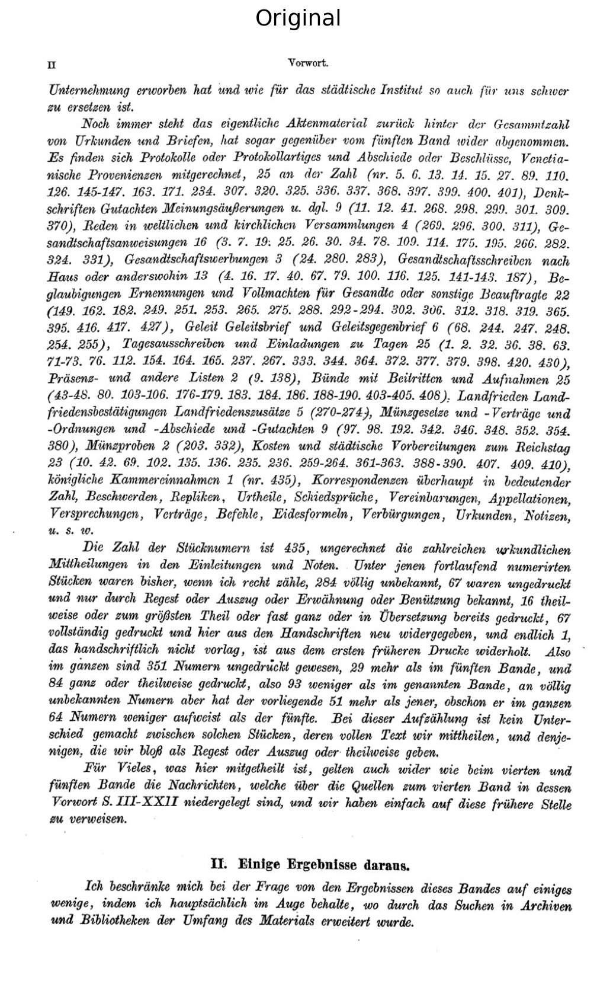

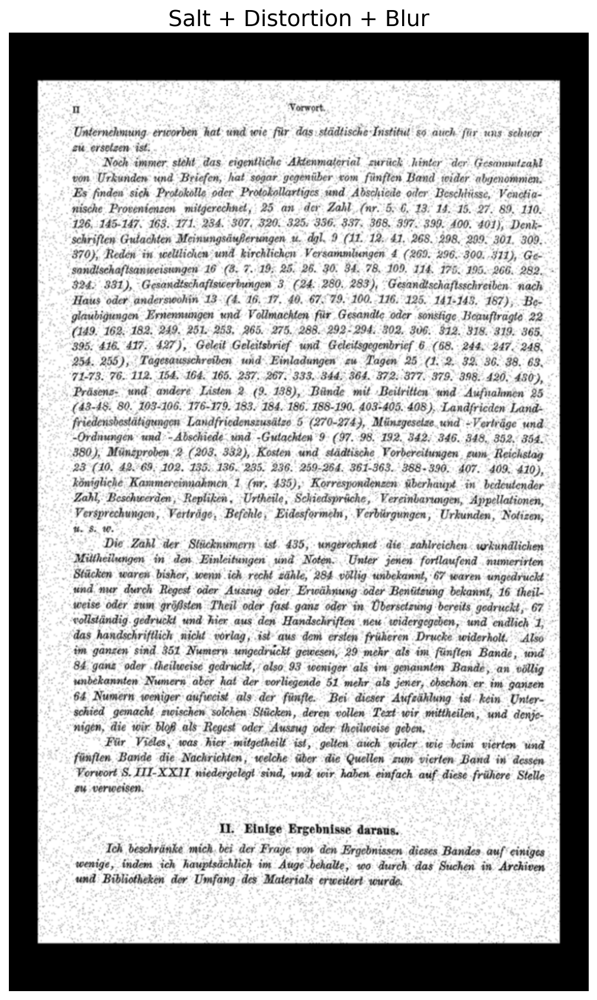

In [27]:
noise_image_test = "images/9.jpg"

img = Image.open(noise_image_test).convert("RGB")
combined_img = apply_all_corruptions(
    img,
    sp_amount=0.04,
    sp_ratio=0.4,
    zoom_scale=0.9,
    resolution_scale = 0.85,
    blur_kernel=3
)
#original
plt.figure(figsize=(10,14), dpi=150)
plt.imshow(img)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

#combined
plt.figure(figsize=(10,14), dpi=150)
plt.imshow(combined_img)
plt.title("Salt + Distortion + Blur", fontsize=18)
plt.axis("off")
plt.show()

### Apply corruption for all images

In [28]:
import os
os.makedirs("corrupted_images", exist_ok=True)

In [29]:
from PIL import Image

for p in pages:
    img = Image.open(f"images/{p}.jpg").convert("RGB")

    combined_img = apply_all_corruptions(
        img,
        sp_amount=0.04,
        sp_ratio=0.4,
        zoom_scale=0.9,
        resolution_scale=0.85,
        blur_kernel=3
    )

    combined_img.save(f"corrupted_images/{p}.jpg")

print("Done saving all corrupted images.")

Done saving all corrupted images.


In [41]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"corrupted_images/{p}.jpg"
    output_path = os.path.join(output_dir_2, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_2)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprecht's ist. Hiemit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nennen 

### Evaluation - Experiment 2

In [30]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [31]:
results_exp2 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 2 - page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_2, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    #compute metrics
    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp2.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 2 - page 8...
Evaluating Experiment 2 - page 9...
Evaluating Experiment 2 - page 12...
Evaluating Experiment 2 - page 38...
Evaluating Experiment 2 - page 53...
Evaluating Experiment 2 - page 78...
Evaluating Experiment 2 - page 94...
Evaluating Experiment 2 - page 105...
Evaluating Experiment 2 - page 114...
Evaluating Experiment 2 - page 115...
Evaluating Experiment 2 - page 210...
Evaluating Experiment 2 - page 314...
Evaluating Experiment 2 - page 316...
Evaluating Experiment 2 - page 384...
Evaluating Experiment 2 - page 457...
Evaluating Experiment 2 - page 468...
Evaluating Experiment 2 - page 490...
Evaluating Experiment 2 - page 619...
Evaluating Experiment 2 - page 615...
Evaluating Experiment 2 - page 753...


In [32]:
print("=== Experiment 2 Results - Gemini-3.1-Pro ===")
df_exp2 = pd.DataFrame(results_exp2)
df_exp2

=== Experiment 2 Results - Gemini-3.1-Pro ===


,page,WER,CER
0,8,0.017370,0.002604
1,9,0.007117,0.001622
2,12,0.032864,0.011681
3,38,0.192878,0.081067
4,53,0.058503,0.019283
5,78,0.079137,0.038936
6,94,0.218855,0.095405
7,105,0.085389,0.029608
8,114,0.129542,0.049446
9,115,0.044046,0.022195


In [45]:
mean_wer_exp2 = df_exp2["WER"].mean()
mean_cer_exp2 = df_exp2["CER"].mean()

print("=== Experiment 2 Results - Gemini-3.1-Pro ===")
print(f"Mean WER: {mean_wer_exp2:.4f}")
print(f"Mean CER: {mean_cer_exp2:.4f}")

=== Experiment 2 Results - Gemini-3.1-Pro ===
Mean WER: 0.0710
Mean CER: 0.0260


### Save Result

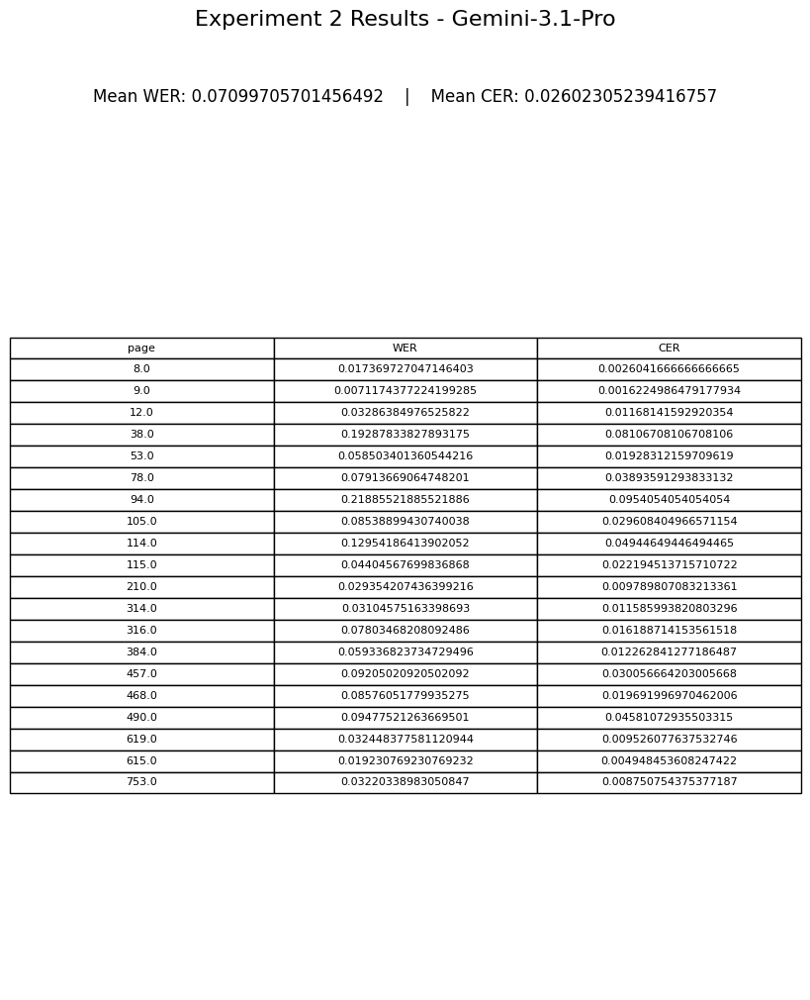

Saved: outputs/Results\experiment_2_results.png


In [33]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp2["WER"].mean()
mean_cer = df_exp2["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_2_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp2) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 2 Results - Gemini-3.1-Pro", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)


table = ax.table(
    cellText=df_exp2.values,
    colLabels=df_exp2.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

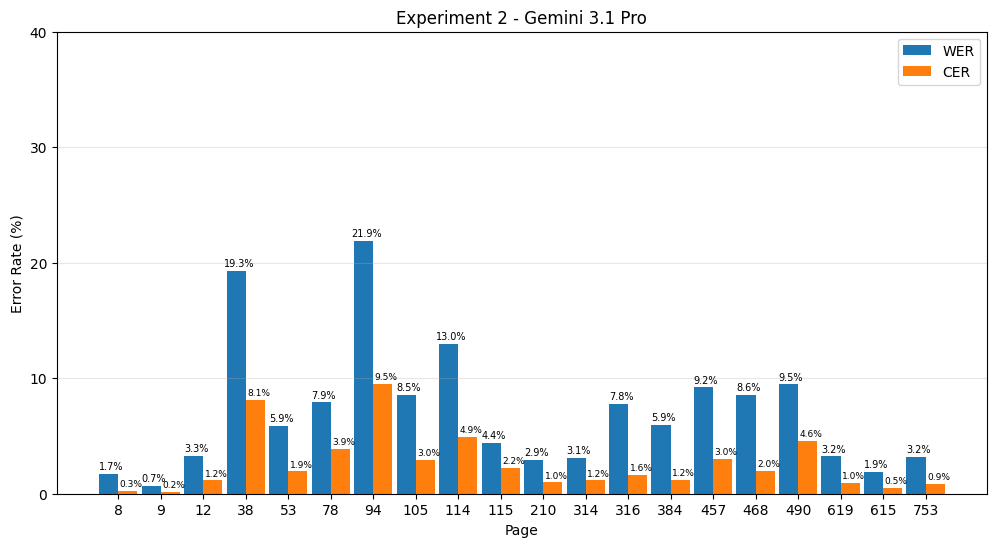

In [94]:
import numpy as np
x = np.arange(len(df_exp2))
width = 0.45

wer_pct = df_exp2["WER"] * 100
cer_pct = df_exp2["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp2["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 2 - Gemini 3.1 Pro")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 40)
plt.yticks(np.arange(0, 41, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_2_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 3 - With Preprocessing

In [42]:
import os

output_dir_3 = "outputs/Experiment_3"
os.makedirs(output_dir_3, exist_ok=True)

### Preprocessing function

In [35]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v3(image):
    img = np.array(image.convert("RGB"))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    upscaled = cv2.resize(
        gray,
        None,
        fx=2,
        fy=2,
        interpolation=cv2.INTER_LANCZOS4
    )


    enhanced = cv2.convertScaleAbs(upscaled, alpha=1.15, beta=2)

    result = enhanced.copy()
    text_mask = result < 190
    result[text_mask] = np.clip(result[text_mask] * 0.75, 0, 255)

    blur = cv2.GaussianBlur(result, (0, 0), 0.8)
    result = cv2.addWeighted(result, 1.4, blur, -0.4, 0)

    result[result > 240] = 255

    return Image.fromarray(result)

### test preprocessing on one image

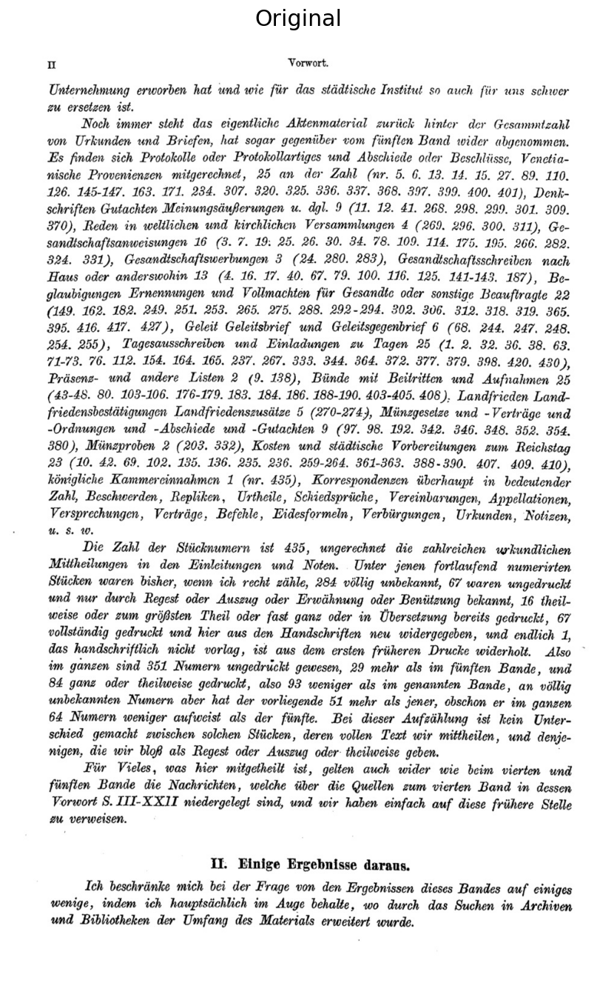

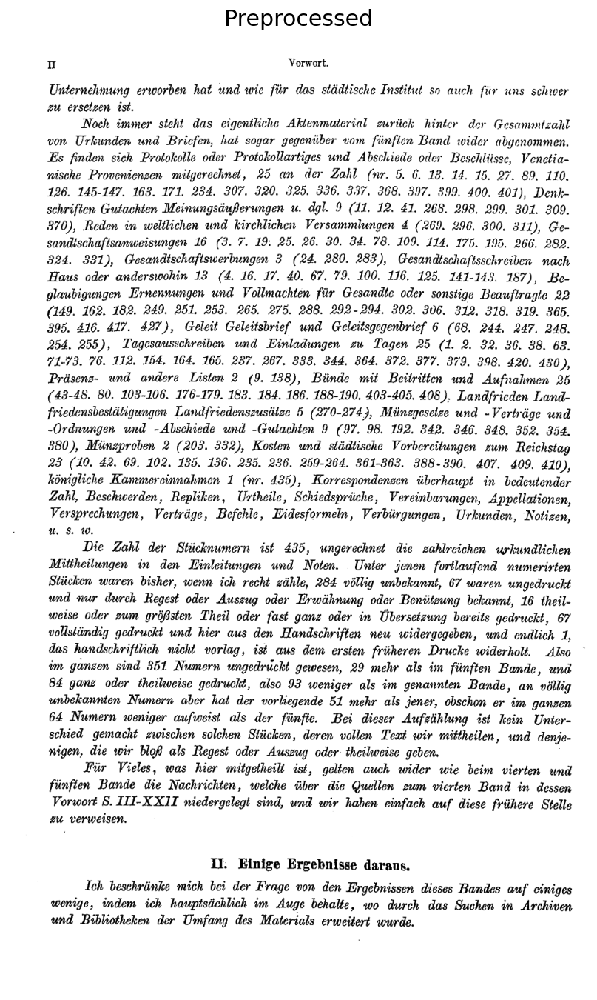

In [36]:
from PIL import Image
import matplotlib.pyplot as plt

test_image_path = "images/9.jpg"

img = Image.open(test_image_path).convert("RGB")
preprocessed_img = preprocess_image_v3(img)

plt.figure(figsize=(10,14), dpi=120)
plt.imshow(img)
plt.title("Original", fontsize=18)
plt.axis("off")
plt.show()

plt.figure(figsize=(10,14), dpi=120)
plt.imshow(preprocessed_img, cmap="gray")
plt.title("Preprocessed", fontsize=18)
plt.axis("off")
plt.show()

In [37]:
import os

os.makedirs("preprocessed_images", exist_ok=True)

### Apply preprocessing to all original images

In [38]:
from PIL import Image

for p in pages:
    img = Image.open(f"images/{p}.jpg").convert("RGB")

    preprocessed_img = preprocess_image_v3(img)

    preprocessed_img.save(f"preprocessed_images/{p}.jpg")

print("Done saving all preprocessed images.")

Done saving all preprocessed images.


### Run Gemini-3.1-Pro on preprocessed images

In [56]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"preprocessed_images/{p}.jpg"
    output_path = os.path.join(output_dir_3, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_2)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprecht's ist. Hiemit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nennen 

In [81]:
# Rerun only selected pages

pages_to_rerun = [468,753]

for p in pages_to_rerun:
    print(f"\n==============================")
    print(f"Re-running Page {p}")
    print(f"==============================")

    image_path = f"preprocessed_images/{p}.jpg"
    output_path = os.path.join(output_dir_3, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_2)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Updated: {output_path}")


Re-running Page 468
F. K. Ruprechts Landfriedensthätigkeit nr. 270-274.                                          457

272. Landfriede zwischen Erzbischof Johann von Mainz Bischof Wilhelm von Pader- 1409
     born und Landgraf Hermann von Hessen auf zehn Jahre schlechthin 1. 1409 Jan. 20
     Jan. 20 Frankfurt.

     K aus Darmstadt St.A. Urkunden, Staatsverträge, Mainz nr. 43 (früher Karlsruhe G.L.A.
5    Badisches Archiv fasc. Verträge mit Mainz) cop. ch. coaev. Folioheft von 8 Seiten
     von denen etwas mehr als 6 beschrieben sind. — Im folgenden sind nur die hier neu
     auftretenden oder in der Form vom Landfrieden von 1408 Dec. 1 nr. 270 stark ab-
     weichenden Partien abgedruckt, die anderen durch Verweisung auf jene Urkunde ge-
     kürzt worden, doch so, daß alle den Sinn berührenden Abweichungen, die K und M
10   gegenüber von nr. 270 gemeinsam sind, hier zu nr. 272 notiert wurden. Wegen der
     übrigen Abweichungen vgl. Varianten zu nr. 270. In diese letzteren sind aufg

### Evaluation -Experiment 3

In [73]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [88]:
results_exp3 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 3 - page {p}...")

    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_3, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)

    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp3.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 3 - page 8...
Evaluating Experiment 3 - page 9...
Evaluating Experiment 3 - page 12...
Evaluating Experiment 3 - page 38...
Evaluating Experiment 3 - page 53...
Evaluating Experiment 3 - page 78...
Evaluating Experiment 3 - page 94...
Evaluating Experiment 3 - page 105...
Evaluating Experiment 3 - page 114...
Evaluating Experiment 3 - page 115...
Evaluating Experiment 3 - page 210...
Evaluating Experiment 3 - page 314...
Evaluating Experiment 3 - page 316...
Evaluating Experiment 3 - page 384...
Evaluating Experiment 3 - page 457...
Evaluating Experiment 3 - page 468...
Evaluating Experiment 3 - page 490...
Evaluating Experiment 3 - page 619...
Evaluating Experiment 3 - page 615...
Evaluating Experiment 3 - page 753...


In [89]:
print("=== Experiment 3 Results - Gemini-3.1-Pro ===")
df_exp3 = pd.DataFrame(results_exp3)
df_exp3

=== Experiment 3 Results - Gemini-3.1-Pro ===


,page,WER,CER
0,8,0.014888,0.002232
1,9,0.007117,0.001622
2,12,0.028169,0.010973
3,38,0.091988,0.028490
4,53,0.044898,0.011797
5,78,0.074820,0.034099
6,94,0.213805,0.094865
7,105,0.087287,0.028017
8,114,0.129542,0.049446
9,115,0.045677,0.022195


In [90]:
mean_wer_exp3 = df_exp3["WER"].mean()
mean_cer_exp3 = df_exp3["CER"].mean()

print("=== Experiment 3 Results - Gemini-3.1-Pro ===")
print(f"Mean WER: {mean_wer_exp3:.4f}")
print(f"Mean CER: {mean_cer_exp3:.4f}")

=== Experiment 3 Results - Gemini-3.1-Pro ===
Mean WER: 0.0671
Mean CER: 0.0267


### Save Result

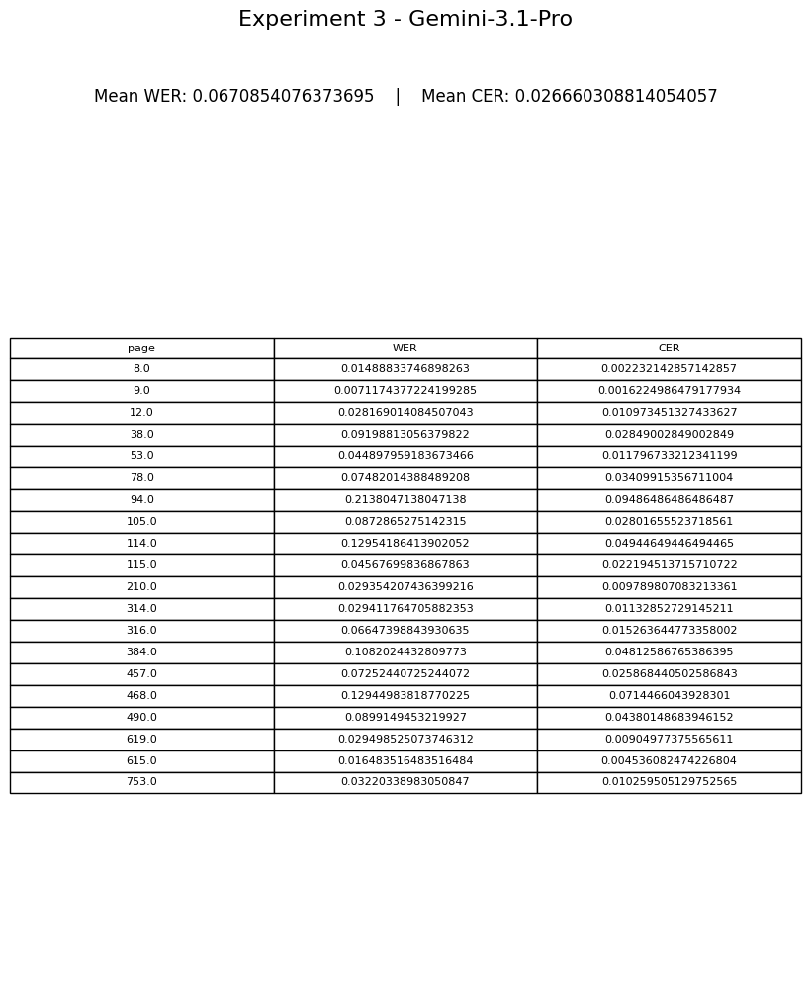

Saved: outputs/Results\experiment_3_results.png


In [91]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp3["WER"].mean()
mean_cer = df_exp3["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_3_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp3) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 3 - Gemini-3.1-Pro", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)

# Table
table = ax.table(
    cellText=df_exp3.values,
    colLabels=df_exp3.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

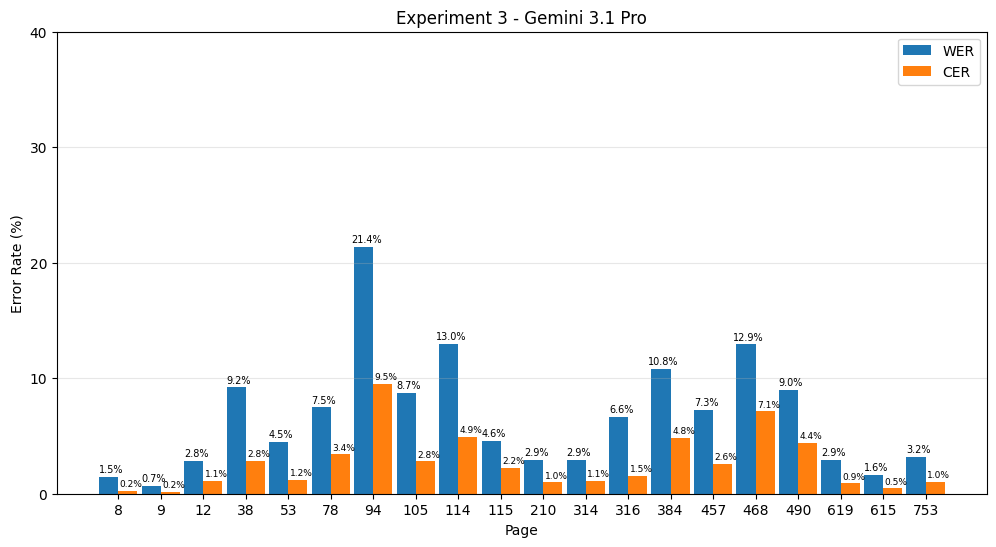

In [95]:
import numpy as np
x = np.arange(len(df_exp3))
width = 0.45

wer_pct = df_exp3["WER"] * 100
cer_pct = df_exp3["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp3["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 3 - Gemini 3.1 Pro")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 40)
plt.yticks(np.arange(0, 41, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_3_gemini_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Experiment 4: With Noise and Preprocessing

In [65]:
import os

output_dir_4 = "outputs/Experiment_4"
os.makedirs(output_dir_4, exist_ok=True)

### Create folder for noisy + preprocessed images

In [66]:
import os

os.makedirs("corrupted_preprocessed_images", exist_ok=True)

In [66]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v2(image):
    img = np.array(image.convert("RGB"))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    #remove black outer border
    mask = gray > 25
    coords = np.argwhere(mask)
    if coords.size > 0:
        y0, x0 = coords.min(axis=0)
        y1, x1 = coords.max(axis=0) + 1
        gray = gray[y0:y1, x0:x1]

    cleaned = gray.copy()

    #cetect dark pixels: text black dots
    dark = cv2.threshold(gray, 160, 255, cv2.THRESH_BINARY_INV)[1]

    
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        dark, connectivity=8
    )

    #remove only very small isolated black dots
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        w = stats[i, cv2.CC_STAT_WIDTH]
        h = stats[i, cv2.CC_STAT_HEIGHT]

        # remove tiny dot-like components, keep text strokes
        if area <= 12 and w <= 4 and h <= 4:
            cleaned[labels == i] = 255

    #improve contrast gently
    cleaned = cv2.normalize(cleaned, None, 0, 255, cv2.NORM_MINMAX)

    #light unsharp mask, no blur output
    blur = cv2.GaussianBlur(cleaned, (0, 0), 1.0)
    sharpened = cv2.addWeighted(cleaned, 1.6, blur, -0.6, 0)

    return Image.fromarray(sharpened)

In [67]:
import cv2
import numpy as np
from PIL import Image

def preprocess_image_v3(image):
    img = np.array(image.convert("RGB"))

    #grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    #sharpening 
    kernel = np.array([
        [0, -0.4, 0],
        [-0.4, 2.5, -0.4],
        [0, -0.4, 0]
    ])
    sharpened = cv2.filter2D(gray, -1, kernel)

    #balanced threshold
    _, binary = cv2.threshold(
        sharpened,
        145,   
        255,
        cv2.THRESH_BINARY
    )

    return Image.fromarray(binary)

### apply preprocessed image to noisy images

In [68]:
from PIL import Image

for p in pages:
    img = Image.open(f"corrupted_images/{p}.jpg").convert("RGB")

    preprocessed_img = preprocess_image_v3(img)

    preprocessed_img.save(f"corrupted_preprocessed_images/{p}.jpg")

print("Done saving corrupted + preprocessed images.")

Done saving corrupted + preprocessed images.


### Test one image

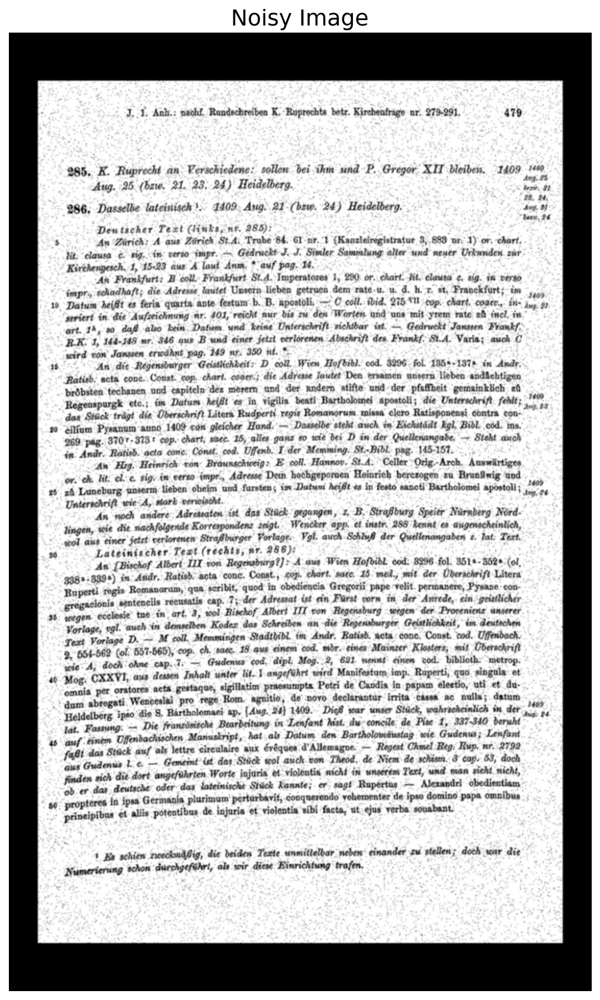

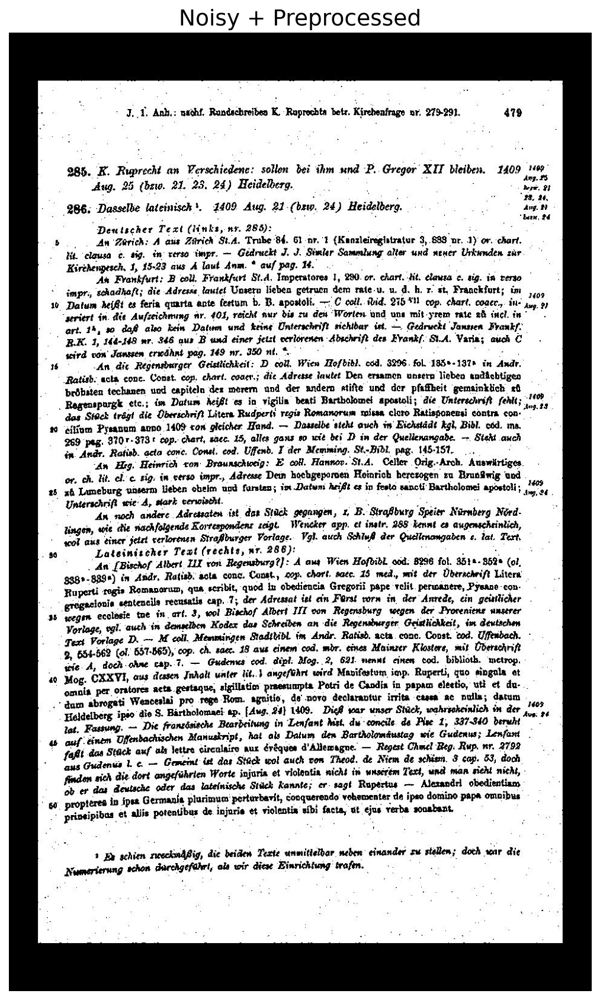

In [69]:
from PIL import Image
import matplotlib.pyplot as plt

test_page = 490

noisy_img = Image.open(f"corrupted_images/{test_page}.jpg").convert("RGB")
preprocessed_img = Image.open(f"corrupted_preprocessed_images/{test_page}.jpg")

plt.figure(figsize=(10,14), dpi=150)
plt.imshow(noisy_img)
plt.title("Noisy Image", fontsize=18)
plt.axis("off")
plt.show()

plt.figure(figsize=(10,14), dpi=150)
plt.imshow(preprocessed_img, cmap="gray")
plt.title("Noisy + Preprocessed", fontsize=18)
plt.axis("off")
plt.show()

### Run Gemini_3.1_Pro model

In [70]:
for p in pages:
    print(f"\n==============================")
    print(f"Page {p}")
    print(f"==============================")

    image_path = f"corrupted_preprocessed_images/{p}.jpg"
    output_path = os.path.join(output_dir_4, f"page_{p}.txt")

    output_text = run_ocr_one_image(image_path, prompt_text_0)

    print(output_text)

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(output_text)

    print(f"Saved: {output_path}")


Page 8
Vorwort.

Das Jahr 1885 brachte die erste Fortsetzung des K. Ruprecht mit dem zweiten
Bande von dessen Regierung, dem fünften der ganzen Reihe. Im Jahr 1887 wurde
die dritte Abtheilung der Zeit K. Sigmund's ausgegeben, der neunte Band der Reichs-
tagsakten. Jetzt nach einem Jahre können wir bereits den sechsten Band mittheilen,
welcher zugleich der dritte und Schlußband K. Ruprecht's ist. Hiemit schließt sich die
Lücke, welche in der Regierung dieses Königs noch auszufüllen war, und die sämmt-
lichen bisher erschienenen neun Bände bilden eine ununterbrochene Kette. Mit dem
zehnten Bande, dessen Ausgabe das nächste sein wird, soll dann auch die Periode K.
Sigmund's zu ihrem Ende kommen.

I. Bearbeitung des vorliegenden Bandes.

Die Leitung des Unternehmens ruht wie bisher in der Hand H. v. Sybel's. Von
früheren Mitarbeitern des Bandes, welche bei den Vorarbeiten überhaupt sowie ins-
besondere bei der Anfertigung von Regesten Auszügen und Abschriften thätig waren,
sind zu nennen 

### Evaluation -Experiment 4

In [71]:
def normalize_text(text):
    text = text.lower()
    text = text.strip()
    text = re.sub(r"\s+", " ", text)
    return text

In [72]:
results_exp4 = []

gold_base = "https://nlp.fi.muni.cz/projekty/ahisto/ocr-output/494/"

for p in pages:
    print(f"Evaluating Experiment 4 - page {p}...")

    
    gold_url = f"{gold_base}{p}.txt"
    gold_text = requests.get(gold_url).text

    pred_path = os.path.join(output_dir_4, f"page_{p}.txt")
    with open(pred_path, "r", encoding="utf-8") as f:
        pred_text = f.read()

    gold_norm = normalize_text(gold_text)
    pred_norm = normalize_text(pred_text)


    wer_score = wer(gold_norm, pred_norm)
    cer_score = cer(gold_norm, pred_norm)

    results_exp4.append({
        "page": p,
        "WER": wer_score,
        "CER": cer_score
    })

Evaluating Experiment 4 - page 8...
Evaluating Experiment 4 - page 9...
Evaluating Experiment 4 - page 12...
Evaluating Experiment 4 - page 38...
Evaluating Experiment 4 - page 53...
Evaluating Experiment 4 - page 78...
Evaluating Experiment 4 - page 94...
Evaluating Experiment 4 - page 105...
Evaluating Experiment 4 - page 114...
Evaluating Experiment 4 - page 115...
Evaluating Experiment 4 - page 146...
Evaluating Experiment 4 - page 210...
Evaluating Experiment 4 - page 314...
Evaluating Experiment 4 - page 316...
Evaluating Experiment 4 - page 457...
Evaluating Experiment 4 - page 468...
Evaluating Experiment 4 - page 490...
Evaluating Experiment 4 - page 619...
Evaluating Experiment 4 - page 615...
Evaluating Experiment 4 - page 753...


In [73]:
print("=== Experiment 4 Results - Gemini-3.1-Pro ===")
df_exp4 = pd.DataFrame(results_exp4)
df_exp4

=== Experiment 4 Results - Gemini-3.1-Pro ===


,page,WER,CER
0,8,0.017370,0.002604
1,9,0.007117,0.001622
2,12,0.030516,0.011327
3,38,0.182493,0.079772
4,53,0.473469,0.372051
5,78,0.520863,0.395647
6,94,0.348485,0.222162
7,105,0.282732,0.191659
8,114,0.129542,0.049200
9,115,0.044046,0.022195


In [74]:
mean_wer_exp4 = df_exp4["WER"].mean()
mean_cer_exp4 = df_exp4["CER"].mean()

print("=== Experiment 4 Results - Gemini-3.1-Pro ===")
print(f"Mean WER: {mean_wer_exp4:.4f}")
print(f"Mean CER: {mean_cer_exp4:.4f}")

=== Experiment 4 Results - Gemini-3.1-Pro ===
Mean WER: 0.1897
Mean CER: 0.1206


#### Save result

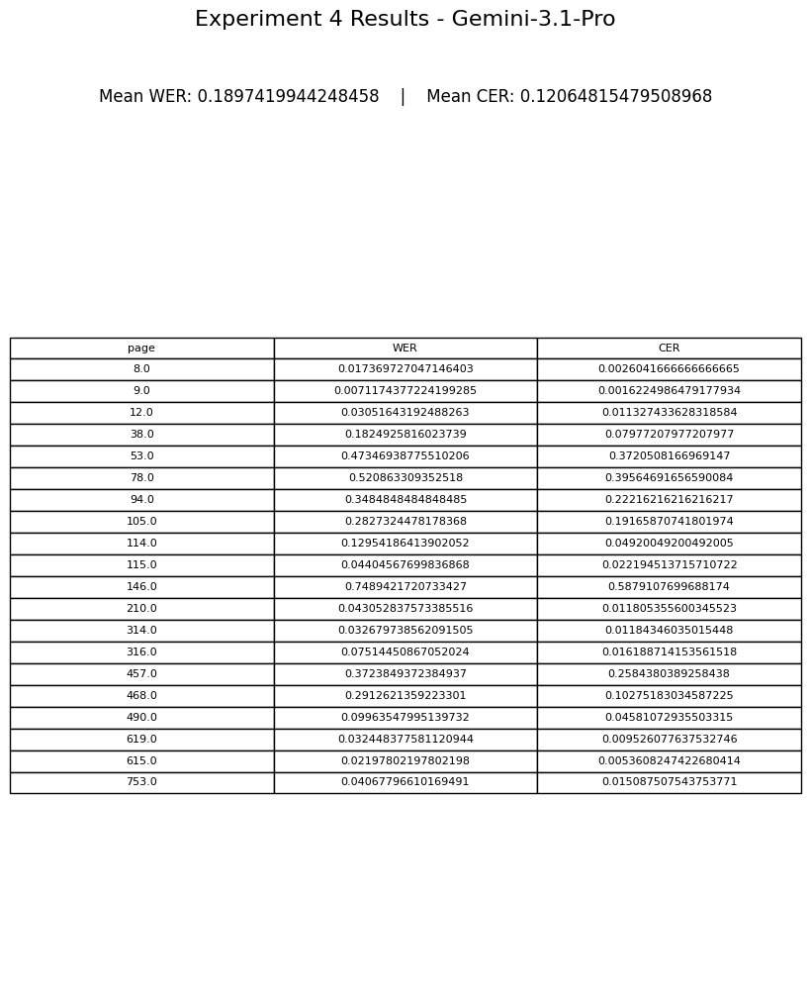

Saved: outputs/Results\experiment_4_results.png


In [76]:
import os
import matplotlib.pyplot as plt

mean_wer = df_exp4["WER"].mean()
mean_cer = df_exp4["CER"].mean()

save_path = os.path.join(output_dir_result_1, "experiment_4_results.png")

fig, ax = plt.subplots(figsize=(10, len(df_exp4) * 0.45 + 2))
ax.axis("off")


fig.suptitle("Experiment 4 Results - Gemini-3.1-Pro", fontsize=16, y=0.98)

summary_text = f"Mean WER: {mean_wer}    |    Mean CER: {mean_cer}"
fig.text(0.5, 0.90, summary_text, ha="center", va="center", fontsize=12)


table = ax.table(
    cellText=df_exp4.values,
    colLabels=df_exp4.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.3)

ax.set_position([0.1, 0.08, 0.8, 0.78])

fig.savefig(save_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Saved:", save_path)

In [ ]:
import numpy as np
x = np.arange(len(df_exp4))
width = 0.45

wer_pct = df_exp4["WER"] * 100
cer_pct = df_exp4["CER"] * 100

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width/2, wer_pct, width, label="WER")
bars2 = plt.bar(x + width/2, cer_pct, width, label="CER")

for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.06,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=7
    )
for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2 + 0.08,
        bar.get_height() + 0.2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=6.5
    )

plt.xticks(x, df_exp4["page"])
plt.xlabel("Page")
plt.ylabel("Error Rate (%)")
plt.title("Experiment 4 - Gemini 3.1 Pro")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.ylim(0, 30)
plt.yticks(np.arange(0, 31, 10))

os.makedirs(output_dir_result_1, exist_ok=True)

plt.savefig(
    os.path.join(
        output_dir_result_1,
        "experiment_4_wer_cer_by_page.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

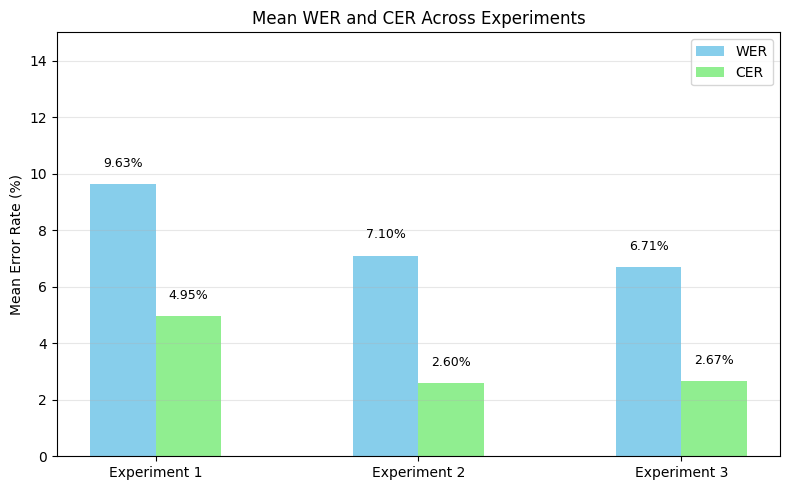

In [97]:
import matplotlib.pyplot as plt
import numpy as np


mean_wer = [
    df_exp1["WER"].mean() * 100,
    df_exp2["WER"].mean() * 100,
    df_exp3["WER"].mean() * 100
]

mean_cer = [
    df_exp1["CER"].mean() * 100,
    df_exp2["CER"].mean() * 100,
    df_exp3["CER"].mean() * 100
]

experiments = [
    "Experiment 1",
    "Experiment 2",
    "Experiment 3"
]
x = np.arange(len(experiments))
width = 0.25        

plt.figure(figsize=(8,5))

bars1 = plt.bar(
    x - width/2,
    mean_wer,
    width,
    color="skyblue",
    label="WER"
)

bars2 = plt.bar(
    x + width/2,
    mean_cer,
    width,
    color="lightgreen",
    label="CER"
)


for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.xticks(x, experiments)
plt.ylabel("Mean Error Rate (%)")
plt.title("Mean WER and CER Across Experiments")

plt.yticks(np.arange(0, 16, 2))
plt.ylim(0, 15)

plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(output_dir_result_1, "three_experiment_summary_Gemini.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()